<a href="https://colab.research.google.com/github/alimoorreza/CS181-fall26-notes/blob/main/cs181_segment_anything_SAM_inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### CS181: Computer Vision, Fall 2026

Tuesday, October 20st, 2026

📆 [Course Schedule](https://analytics.drake.edu/~reza/teaching/cs181_fall26/cs181_schedule.html) | 📜 [Syllabus](https://analytics.drake.edu/~reza/teaching/cs181_fall26/cs181_syllabus_fall26.pdf)


# Automatically generating object masks with [Segment Anything (SAM) version#1](https://segment-anything.com/)

## Environment Set-up

Make sure you select your __Runtime__ mode to __'T4 GPU'__
It should look as follows:
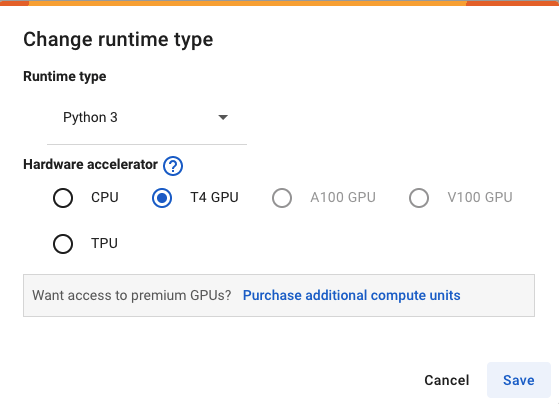

In [1]:
using_colab = True
if using_colab:
    import torch
    import torchvision
    print("PyTorch version:", torch.__version__)
    print("Torchvision version:", torchvision.__version__)
    print("CUDA is available:", torch.cuda.is_available())
    import sys
    !{sys.executable} -m pip install opencv-python matplotlib
    !{sys.executable} -m pip install 'git+https://github.com/facebookresearch/segment-anything.git'

    !mkdir images
    !wget -P images https://analytics.drake.edu/~reza/teaching/cs195_fall24/datasets/Crocodile_27.png

    !wget https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA is available: True
  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-_nw5ihye
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-_nw5ihye
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Preparing metadata (setup.py) ... done
  Created wheel for segment_anything: filename=segment_anything-1.0-py3-none-any.whl size=36634 sha256=52f0e495862722f2fbb0eff3cc26c3a8f523f0e1a2fef68692e99d25e0a7efb5
  Stored in directory: /tmp/pip-ephem-wheel-cache-zjwii1np/wheels/5d/7b/4a/c7fda89f2e27647dd0816f51ea103992b1b6f0f53ad234895c
Successfully built segment_anything
--2026-10-20 18:24:57--  https://analytics.drake.edu/~reza/teaching/cs195_fall24/datasets/Crocodile_27.png
Resolving analytics.drake.edu (analytics.drake.edu)... 198.7.223.92
Connectin

## Set-up

In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2
import sys
import os
import pickle
sys.path.append("..")
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor


def show_anns(anns):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)
    polygons = []
    color = []
    for ann in sorted_anns:
        m = ann['segmentation']
        img = np.ones((m.shape[0], m.shape[1], 3))
        color_mask = np.random.random((1, 3)).tolist()[0]
        for i in range(3):
            img[:,:,i] = color_mask[i]
        ax.imshow(np.dstack((img, m*0.35)))


sam_checkpoint = "sam_vit_h_4b8939.pth"
model_type     = "vit_h"

device         = "cuda"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)


# To run automatic mask generation, provide a SAM model to the SamAutomaticMaskGenerator class.
# Set the path below to the SAM checkpoint. Running on CUDA and with the default model is recommended.
mask_generator_1  = SamAutomaticMaskGenerator(sam)

# There are several tunable parameters in automatic mask generation that control how densely points are
# sampled and what the thresholds are for removing low quality or duplicate masks. Additionally, generation
# can be automatically run on crops of the image to get improved performance on smaller objects, and
# post-processing can remove stray pixels and holes. Here is an example configuration that samples more masks:
mask_generator_2 = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,
    pred_iou_thresh=0.86,
    stability_score_thresh=0.92,
    crop_n_layers=1,
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,  # Requires open-cv to run post-processing
)


In [4]:
%%shell
mkdir images
wget -P images https://analytics.drake.edu/~reza/teaching/cs181_fall26/datasets/horse.jpg
wget -P images https://analytics.drake.edu/~reza/teaching/cs181_fall26/datasets/seal.jpg

mkdir: cannot create directory ‘images’: File exists
--2026-10-20 18:27:17--  https://analytics.drake.edu/~reza/teaching/cs181_fall26/datasets/horse.jpg
Resolving analytics.drake.edu (analytics.drake.edu)... 198.7.223.92
Connecting to analytics.drake.edu (analytics.drake.edu)|198.7.223.92|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 33352 (33K) [image/jpeg]
Saving to: ‘images/horse.jpg’

horse.jpg           100%[===================>]  32.57K  --.-KB/s    in 0.06s   

2026-10-20 18:27:17 (510 KB/s) - ‘images/horse.jpg’ saved [33352/33352]

--2026-10-20 18:27:17--  https://analytics.drake.edu/~reza/teaching/cs181_fall26/datasets/seal.jpg
Resolving analytics.drake.edu (analytics.drake.edu)... 198.7.223.92
Connecting to analytics.drake.edu (analytics.drake.edu)|198.7.223.92|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 35943 (35K) [image/jpeg]
Saving to: ‘images/seal.jpg’

seal.jpg            100%[===================>]  35.10K  --.-K

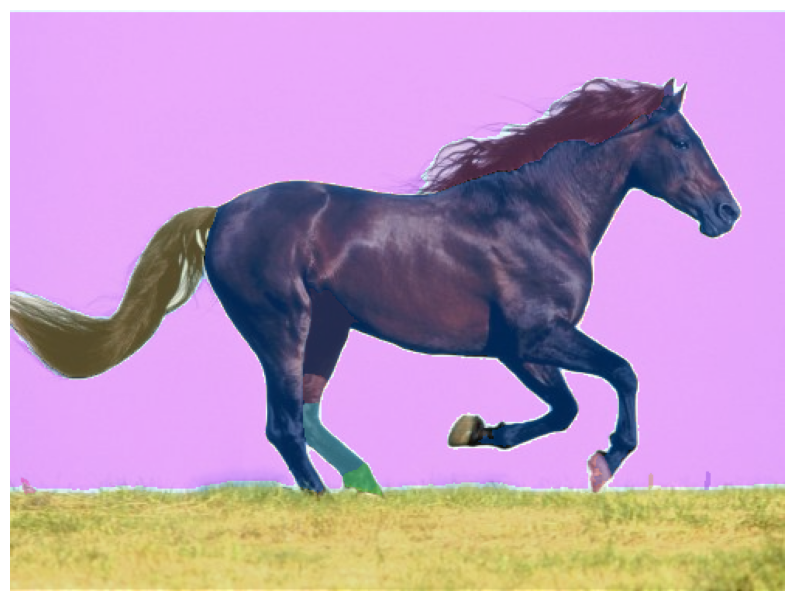

In [15]:
root_dir            = "/content/images/"
is_display_enabled  = True

'''
file_mask_params 	  = open(dest_root_dir + "mask_params_for_SAM.txt", "w")
sam_mask_params     = "points_per_side=32 \n" + \
                      "pred_iou_thresh=0.86 \n" + \
                      "stability_score_thresh=0.92 \n" + \
                      "crop_n_layers=1 \n" + \
                      "crop_n_points_downscale_factor=2 \n" + \
                      "min_mask_region_area=100,  # Requires open-cv to run post-processing \n"
file_mask_params.write(sam_mask_params)
file_mask_params.close()
'''

#cur_image = 'seal.jpg'
cur_image   = 'horse.jpg'

image       = cv2.imread(root_dir + cur_image)
image       = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
masks2      = mask_generator_2.generate(image)

if is_display_enabled == True:
  plt.figure(figsize=(10,10))
  plt.imshow(image)
  show_anns(masks2)
  plt.axis('off')
  plt.show()


# ---- save the mask ----
# make a directory for each animal
cur_animal    = cur_image.split("/")[0]
dest_dir 	    = root_dir + "/"

# save the masks + image as pickle file
f1      = open(dest_dir + cur_image[0:-4] + '.pkl', 'wb')
my_dict = {'image': image, 'masks': masks2}
pickle.dump(my_dict, f1)
f1.close()


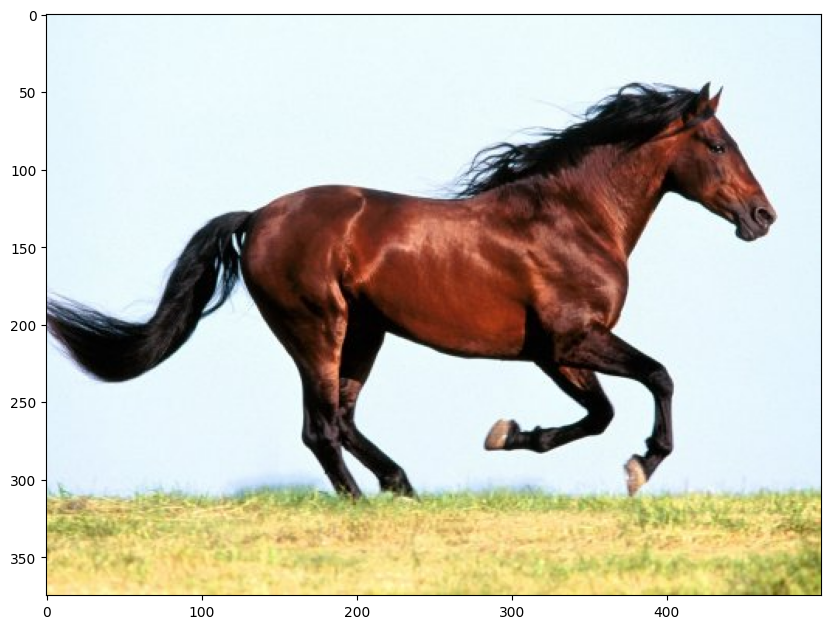

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
plt.imshow(image)

## Example image to generate and show different masks

14
(375, 500)


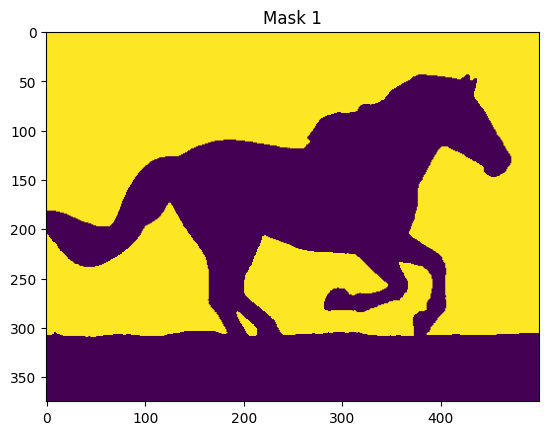

In [17]:
sorted_anns = sorted(masks2, key=(lambda x: x['area']), reverse=True)
print(len(sorted_anns))
cur_ann = sorted_anns[0]
#print(cur_ann.keys()) # dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])
print(cur_ann['segmentation'].shape)
plt.imshow(cur_ann['segmentation'])
plt.title('Mask 1')
plt.show()

(375, 500)


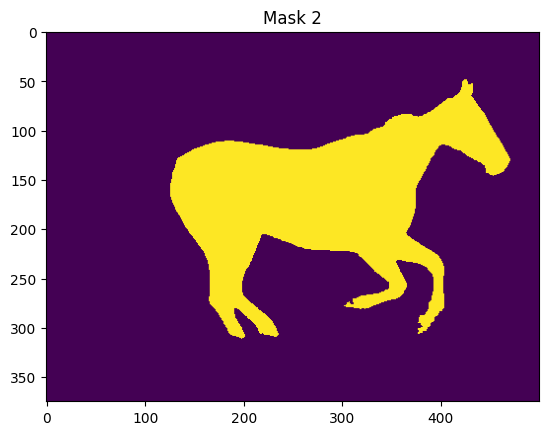

In [18]:
cur_ann = sorted_anns[1]
#print(cur_ann.keys()) # dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])
print(cur_ann['segmentation'].shape)
plt.imshow(cur_ann['segmentation'])
plt.title('Mask 2')
plt.show()

(375, 500)


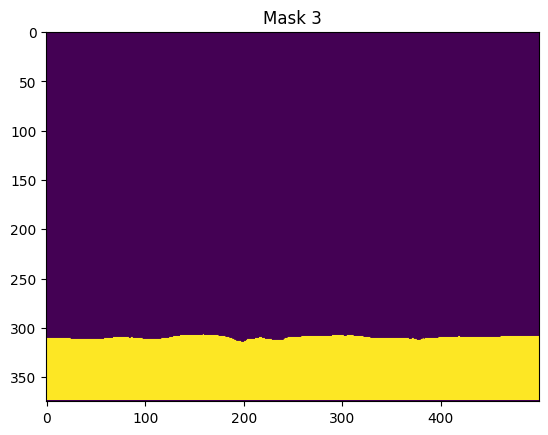

In [19]:
cur_ann = sorted_anns[2]
#print(cur_ann.keys()) # dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])
print(cur_ann['segmentation'].shape)
plt.imshow(cur_ann['segmentation'])
plt.title('Mask 3')
plt.show()

(375, 500)


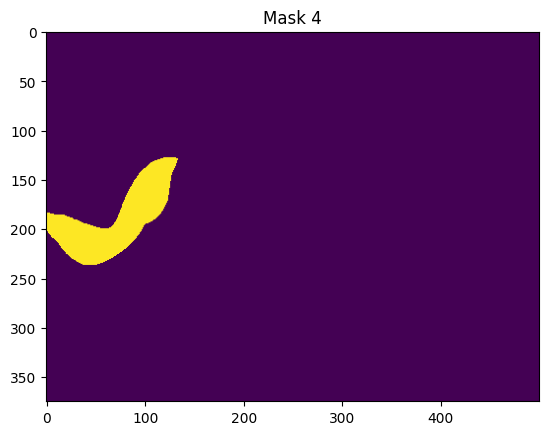

In [20]:
cur_ann = sorted_anns[3]
#print(cur_ann.keys()) # dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])
print(cur_ann['segmentation'].shape)
plt.imshow(cur_ann['segmentation'])
plt.title('Mask 4')
plt.show()

(375, 500)


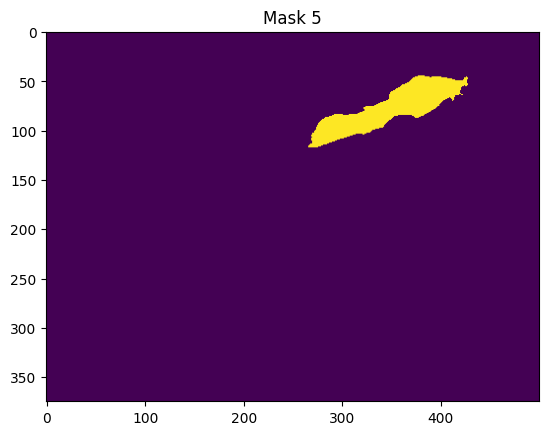

In [21]:
cur_ann = sorted_anns[4]
#print(cur_ann.keys()) # dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])
print(cur_ann['segmentation'].shape)
plt.imshow(cur_ann['segmentation'])
plt.title('Mask 5')
plt.show()

(375, 500)


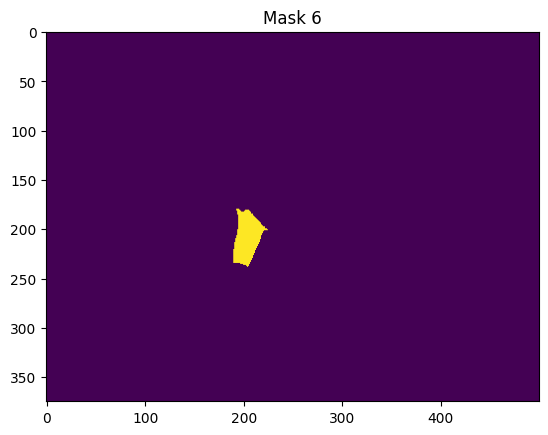

In [22]:
cur_ann = sorted_anns[5]
#print(cur_ann.keys()) # dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])
print(cur_ann['segmentation'].shape)
plt.imshow(cur_ann['segmentation'])
plt.title('Mask 6')
plt.show()

(375, 500)


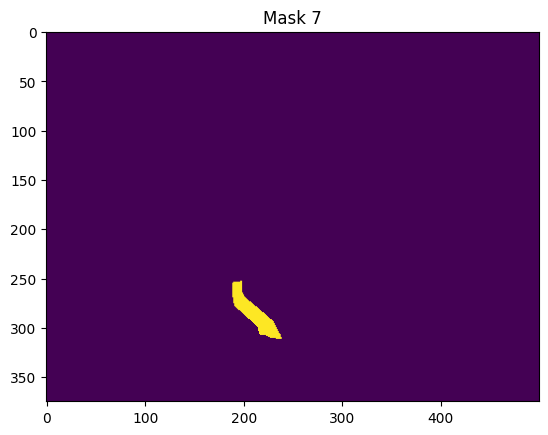

In [23]:
cur_ann = sorted_anns[6]
#print(cur_ann.keys()) # dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])
print(cur_ann['segmentation'].shape)
plt.imshow(cur_ann['segmentation'])
plt.title('Mask 7')
plt.show()

(375, 500)


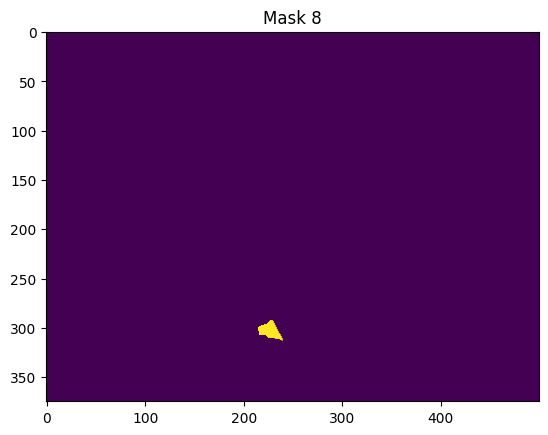

In [24]:
cur_ann = sorted_anns[7]
#print(cur_ann.keys()) # dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])
print(cur_ann['segmentation'].shape)
plt.imshow(cur_ann['segmentation'])
plt.title('Mask 8')
plt.show()

#**Group task#1**
> ### **Task 1: Run Vision Foundation Model Segment Anything (SAM) on a random image of your choice to test its segmentation ability**

In [ ]:
# your code
# ...
# ...
# ...

> ### **Task 2: Summarize your observations and discuss them with your group members.**

>> Observe different masks and discuss it with your table-mates.



>> How many segmentation masks are needed to cover approximately 95% or more of the images?

